# ĐỒ ÁN KHAI PHÁ DỮ LIỆU — BDG2
Dự báo điện và phát hiện bất thường.

## 1. Khai báo thư viện và đường dẫn

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

pd.set_option('display.max_columns', 25)
RANDOM_STATE = 42
DATA_DIR = Path(r'D:\KhaiPhaDuLieu\nhom\dataset\data')
OUTPUT_DIR = Path('bdg2_ket_qua')
OUTPUT_DIR.mkdir(exist_ok=True)
MODE = 'FULL'       # 'TEST': thử 20 tòa; 'FULL': tất cả tòa đủ điều kiện
SO_TOA_TEST = 20
BUILDING_ID = None 
np.random.seed(RANDOM_STATE)
train_end = pd.Timestamp('2017-01-01')
val_end = pd.Timestamp('2017-07-01')


### 1.1. Kiểm tra các file dữ liệu

In [2]:
paths = {
    'raw': DATA_DIR / 'meters/raw/electricity.csv',
    'clean': DATA_DIR / 'meters/cleaned/electricity_cleaned.csv',
    'meta': DATA_DIR / 'metadata/metadata.csv',
    'weather': DATA_DIR / 'weather/weather.csv'
}
for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(f'Không tìm thấy file: {path}')
    with path.open('rb') as f:
        if f.read(80).startswith(b'version https://git-lfs.github.com/spec/v1'):
            raise ValueError(f'{path} là Git LFS pointer, chưa phải dữ liệu CSV.')

## 2. Đọc dữ liệu và hiển thị thông tin

In [3]:
meta = pd.read_csv(paths['meta'])
weather = pd.read_csv(paths['weather'])
raw_cols = pd.read_csv(paths['raw'], nrows=0).columns.tolist()
clean_cols = pd.read_csv(paths['clean'], nrows=0).columns.tolist()
print('Số cột raw:', len(raw_cols))
print('Số cột cleaned:', len(clean_cols))
print('Metadata:', meta.shape, '| Weather:', weather.shape)
display(meta.head(10))
display(weather.head(10))
print('Các cột metadata:', meta.columns.tolist())
print('Các cột weather:', weather.columns.tolist())

Số cột raw: 1579
Số cột cleaned: 1579
Metadata: (1636, 32) | Weather: (331166, 10)


,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,timezone,electricity,...,subindustry,heatingtype,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,US/Eastern,NaN,...,NaN,NaN,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,US/Eastern,NaN,...,NaN,NaN,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,US/Eastern,NaN,...,NaN,NaN,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,US/Eastern,Yes,...,NaN,NaN,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,US/Eastern,Yes,...,NaN,NaN,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN
5,Panther_office_Daina,Panther,NaN,0.0,Office,Office,133.8,1440.0,28.517689,-81.379039,US/Eastern,NaN,...,NaN,NaN,1983.0,NaN,NaN,NaN,NaN,1983,NaN,NaN,NaN,NaN
6,Panther_education_Mattie,Panther,2.0,0.0,Education,Classroom,499.4,5376.0,28.517689,-81.379039,US/Eastern,Yes,...,NaN,NaN,1991.0,NaN,NaN,NaN,NaN,49,NaN,NaN,NaN,NaN
7,Panther_office_Woodrow,Panther,NaN,0.0,Office,Office,537.8,5789.0,28.517689,-81.379039,US/Eastern,NaN,...,NaN,NaN,1996.0,NaN,NaN,NaN,NaN,136,NaN,NaN,NaN,NaN
8,Panther_education_Diann,Panther,3.0,0.0,Education,Classroom,2200.4,23685.0,28.517689,-81.379039,US/Eastern,Yes,...,NaN,NaN,2002.0,NaN,NaN,NaN,NaN,145,NaN,NaN,NaN,NaN
9,Panther_education_Gina,Panther,4.0,0.0,Education,Research,10833.1,116607.0,28.517689,-81.379039,US/Eastern,Yes,...,NaN,NaN,1975.0,NaN,NaN,NaN,NaN,546,NaN,NaN,NaN,NaN


,timestamp,site_id,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
0,2016-01-01 00:00:00,Panther,19.4,NaN,19.4,0.0,NaN,NaN,0.0,0.0
1,2016-01-01 01:00:00,Panther,21.1,6.0,21.1,-1.0,NaN,1019.4,0.0,0.0
2,2016-01-01 02:00:00,Panther,21.1,NaN,21.1,0.0,NaN,1018.8,210.0,1.5
3,2016-01-01 03:00:00,Panther,20.6,NaN,20.0,0.0,NaN,1018.1,0.0,0.0
4,2016-01-01 04:00:00,Panther,21.1,NaN,20.6,0.0,NaN,1019.0,290.0,1.5
5,2016-01-01 05:00:00,Panther,21.1,NaN,20.6,-1.0,NaN,1018.4,0.0,0.0
6,2016-01-01 06:00:00,Panther,20.6,NaN,20.0,0.0,NaN,1018.9,0.0,0.0
7,2016-01-01 07:00:00,Panther,18.9,6.0,18.9,0.0,0.0,1019.2,210.0,1.5
8,2016-01-01 08:00:00,Panther,20.0,NaN,20.0,0.0,NaN,1019.6,0.0,0.0
9,2016-01-01 09:00:00,Panther,21.7,NaN,21.1,0.0,NaN,1020.1,0.0,0.0


Các cột metadata: ['building_id', 'site_id', 'building_id_kaggle', 'site_id_kaggle', 'primaryspaceusage', 'sub_primaryspaceusage', 'sqm', 'sqft', 'lat', 'lng', 'timezone', 'electricity', 'hotwater', 'chilledwater', 'steam', 'water', 'irrigation', 'solar', 'gas', 'industry', 'subindustry', 'heatingtype', 'yearbuilt', 'date_opened', 'numberoffloors', 'occupants', 'energystarscore', 'eui', 'site_eui', 'source_eui', 'leed_level', 'rating']
Các cột weather: ['timestamp', 'site_id', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed']


### 2.1. Xem cấu trúc và thống kê mô tả

In [4]:
meta.info()
weather.info()
display(meta.describe(include='all').T.head(20))
display(weather.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1636 entries, 0 to 1635
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   building_id            1636 non-null   object 
 1   site_id                1636 non-null   object 
 2   building_id_kaggle     1449 non-null   float64
 3   site_id_kaggle         1599 non-null   float64
 4   primaryspaceusage      1615 non-null   object 
 5   sub_primaryspaceusage  1615 non-null   object 
 6   sqm                    1636 non-null   float64
 7   sqft                   1636 non-null   float64
 8   lat                    1399 non-null   float64
 9   lng                    1399 non-null   float64
 10  timezone               1636 non-null   object 
 11  electricity            1578 non-null   object 
 12  hotwater               185 non-null    object 
 13  chilledwater           555 non-null    object 
 14  steam                  370 non-null    object 
 15  wate

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
building_id,1636,1636,Panther_lodging_Dean,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
site_id,1636,19,Rat,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_id_kaggle,1449.0,NaN,NaN,NaN,724.0,418.434583,0.0,362.0,724.0,1086.0,1448.0
site_id_kaggle,1599.0,NaN,NaN,NaN,6.722326,4.94353,0.0,3.0,5.0,12.0,15.0
primaryspaceusage,1615,16,Education,617,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_primaryspaceusage,1615,104,Office,306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sqm,1636.0,NaN,NaN,NaN,8224.033068,10050.121946,26.3,1936.925,5074.4,10360.675,81290.1
sqft,1636.0,NaN,NaN,NaN,88522.795232,108178.666361,283.0,20849.0,54620.5,111521.0,875000.0
lat,1399.0,NaN,NaN,NaN,39.996887,7.403876,28.517689,33.424425,38.903504,44.978782,53.3498
lng,1399.0,NaN,NaN,NaN,-73.779899,36.795109,-122.260729,-97.7431,-77.005349,-76.485292,6.2603


,count,mean,std,min,25%,50%,75%,max
airTemperature,331038.0,14.235343,9.990392,-28.9,7.8,14.4,21.1,48.3
cloudCoverage,160179.0,1.920907,2.550744,0.0,0.0,0.0,4.0,9.0
dewTemperature,330838.0,7.649370,9.201438,-35.0,1.8,8.5,13.9,26.7
precipDepth1HR,197980.0,0.955738,8.273852,-1.0,0.0,0.0,0.0,597.0
precipDepth6HR,18162.0,13.536560,43.801017,-1.0,0.0,0.0,5.0,770.0
seaLvlPressure,309542.0,1016.063498,8.052463,968.2,1011.6,1016.2,1020.9,1050.1
windDirection,318161.0,184.391299,111.571354,0.0,90.0,200.0,280.0,360.0
windSpeed,330592.0,3.569554,2.335197,0.0,2.1,3.1,5.0,24.2


### 2.2. Chọn tòa nhà để đọc

In [5]:
meta = meta.drop_duplicates('building_id')
ids = sorted((set(raw_cols) & set(clean_cols) & set(meta.building_id)) - {'timestamp'})
if MODE == 'TEST':
    rng = np.random.default_rng(RANDOM_STATE)
    ids = sorted(rng.choice(ids, size=min(SO_TOA_TEST, len(ids)), replace=False).tolist())
print('Số tòa được đọc:', len(ids))
print('Một số ID:', ids[:8])

Số tòa được đọc: 1578
Một số ID: ['Bear_assembly_Angel', 'Bear_assembly_Beatrice', 'Bear_assembly_Danial', 'Bear_assembly_Diana', 'Bear_assembly_Genia', 'Bear_assembly_Harry', 'Bear_assembly_Jose', 'Bear_assembly_Roxy']


### 2.3. Đọc raw và cleaned

In [6]:
def doc_dien(path, ten_cot, building_ids):
    parts = []
    for chunk in pd.read_csv(path, usecols=['timestamp'] + building_ids,
                             chunksize=1000, low_memory=False):
        part = chunk.melt(id_vars='timestamp', var_name='building_id', value_name=ten_cot)
        part[ten_cot] = pd.to_numeric(part[ten_cot], errors='coerce').astype('float32')
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

# Electricity RAW là dữ liệu quan sát gốc.
raw = doc_dien(paths['raw'], 'raw_kwh', ids)
# Cleaned chỉ dùng để so sánh và lấy nhãn huấn luyện đáng tin cậy hơn.
clean = doc_dien(paths['clean'], 'clean_kwh', ids)
print('Raw:', raw.shape, '| Cleaned:', clean.shape)
display(raw.head())

Raw: (27684432, 3) | Cleaned: (27684432, 3)


,timestamp,building_id,raw_kwh
0,2016-01-01 00:00:00,Panther_parking_Lorriane,0.0
1,2016-01-01 01:00:00,Panther_parking_Lorriane,0.0
2,2016-01-01 02:00:00,Panther_parking_Lorriane,0.0
3,2016-01-01 03:00:00,Panther_parking_Lorriane,0.0
4,2016-01-01 04:00:00,Panther_parking_Lorriane,0.0


### 2.4. Thông tin và thống kê của dữ liệu điện

In [7]:
raw.info()
display(raw[['raw_kwh']].describe())
print('Số tòa:', raw.building_id.nunique())
print('Số dữ liệu trống:', raw.raw_kwh.isna().sum())
print('Số giá trị âm:', raw.raw_kwh.lt(0).sum())
print('Số giá trị bằng 0:', raw.raw_kwh.eq(0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27684432 entries, 0 to 27684431
Data columns (total 3 columns):
 #   Column       Dtype  
---  ------       -----  
 0   timestamp    object 
 1   building_id  object 
 2   raw_kwh      float32
dtypes: float32(1), object(2)
memory usage: 528.0+ MB


,raw_kwh
count,2.637234e+07
mean,1.385418e+02
std,2.645454e+02
min,0.000000e+00
25%,1.583330e+01
50%,5.437720e+01
75%,1.496289e+02
max,2.212280e+05


Số tòa: 1578
Số dữ liệu trống: 1312095
Số giá trị âm: 0
Số giá trị bằng 0: 1159758


## 3. Khám phá dữ liệu ban đầu (EDA)

In [8]:
sample_ids = ids[:min(5, len(ids))]
summary = raw[raw.building_id.isin(sample_ids)].groupby('building_id')['raw_kwh'].describe()
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max
building_id,,,,,,,,
Bear_assembly_Angel,14435.0,494.34,172.03,36.50,345.02,501.25,633.50,1105.60
Bear_assembly_Beatrice,17505.0,42.96,15.63,1.75,34.25,37.50,55.00,83.00
Bear_assembly_Danial,12187.0,160.66,35.77,68.54,134.04,160.52,187.60,282.92
Bear_assembly_Diana,15280.0,0.86,0.35,0.00,0.60,0.69,1.16,2.51
Bear_assembly_Genia,17377.0,261.09,79.93,151.32,205.71,234.61,284.74,613.51


### 3.1. Biểu đồ phân bố điện năng

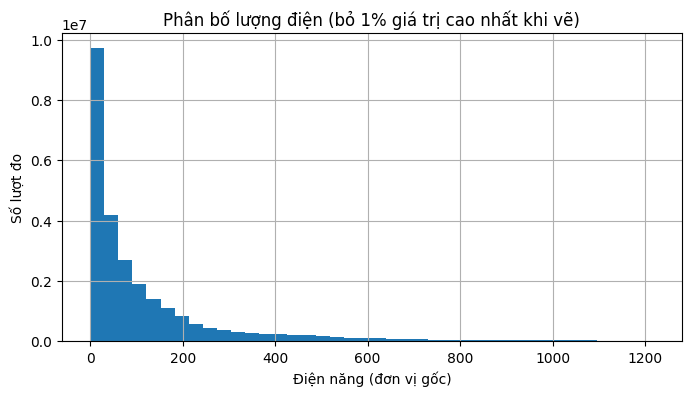

In [9]:
values = raw.raw_kwh.dropna()
upper = values.quantile(0.99)
values[values.between(0, upper)].hist(bins=40, figsize=(8, 4))
plt.title('Phân bố lượng điện (bỏ 1% giá trị cao nhất khi vẽ)')
plt.xlabel('Điện năng (đơn vị gốc)')
plt.ylabel('Số lượt đo')
plt.show()

### 3.2. Tỷ lệ dữ liệu thiếu theo tòa

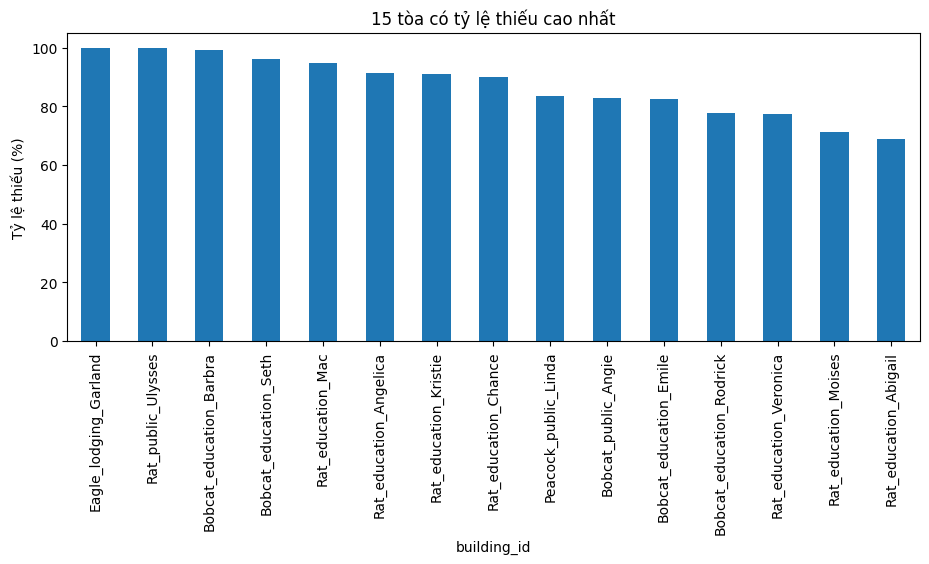

In [10]:
missing = raw.groupby('building_id').raw_kwh.apply(lambda s: s.isna().mean() * 100)
missing.sort_values(ascending=False).head(15).plot.bar(figsize=(11, 4))
plt.title('15 tòa có tỷ lệ thiếu cao nhất')
plt.ylabel('Tỷ lệ thiếu (%)')
plt.show()

## 4. Tiền xử lý dữ liệu
Kiểm tra thiếu, trùng và giá trị sai. Không xóa tất cả giá trị quá cao vì đó có thể là bất thường thật.

In [11]:
raw['timestamp'] = pd.to_datetime(raw['timestamp'], errors='coerce')
clean['timestamp'] = pd.to_datetime(clean['timestamp'], errors='coerce')
print('Raw trùng khóa:', raw.duplicated(['building_id', 'timestamp']).sum())
print('Clean trùng khóa:', clean.duplicated(['building_id', 'timestamp']).sum())
print('Thời gian lỗi:', raw.timestamp.isna().sum())

Raw trùng khóa: 0
Clean trùng khóa: 0
Thời gian lỗi: 0


### 4.1. Làm sạch khóa thời gian trong Electricity
Kiểm tra trùng, bỏ thời điểm lỗi; dữ liệu điện gốc vẫn được giữ để tìm bất thường.

In [12]:
raw = raw.dropna(subset=['timestamp']).copy()
clean = clean.dropna(subset=['timestamp']).copy()
raw = raw.groupby(['building_id', 'timestamp'], as_index=False)['raw_kwh'].mean()
clean = clean.groupby(['building_id', 'timestamp'], as_index=False)['clean_kwh'].mean()
df = raw.copy()
print('Bảng Electricity sau xử lý:', df.shape)
display(df.head())

Bảng Electricity sau xử lý: (27684432, 3)


,building_id,timestamp,raw_kwh
0,Bear_assembly_Angel,2016-01-01 00:00:00,237.850006
1,Bear_assembly_Angel,2016-01-01 01:00:00,221.250000
2,Bear_assembly_Angel,2016-01-01 02:00:00,222.500000
3,Bear_assembly_Angel,2016-01-01 03:00:00,221.399994
4,Bear_assembly_Angel,2016-01-01 04:00:00,224.250000


### 4.2. Tạo các mốc giờ liên tục cho từng tòa

In [13]:
df = df.sort_values(['building_id', 'timestamp'])
hours = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq='h')
full_index = pd.MultiIndex.from_product([ids, hours], names=['building_id', 'timestamp'])
df = df.set_index(['building_id', 'timestamp']).reindex(full_index).reset_index()
print('Sau khi bổ sung mốc giờ:', df.shape)

Sau khi bổ sung mốc giờ: (27684432, 3)


### 4.3. Kiểm tra số điện âm và dữ liệu thiếu
Không tự động xóa các giá trị điện cao: đó có thể là bất thường thực tế.

In [14]:
df.loc[df.raw_kwh < 0, 'raw_kwh'] = np.nan
print('Số giờ thiếu số điện:', df.raw_kwh.isna().sum())
print('Số giờ có số điện bằng 0:', df.raw_kwh.eq(0).sum())
print('Số tòa:', df.building_id.nunique())

Số giờ thiếu số điện: 1312095
Số giờ có số điện bằng 0: 1159758
Số tòa: 1578


### 4.4. Kiểm tra ngoại lệ bằng IQR

In [15]:
q1 = df.groupby('building_id').raw_kwh.quantile(0.25)
q3 = df.groupby('building_id').raw_kwh.quantile(0.75)
limit = q3 + 1.5 * (q3 - q1)
df = df.join(limit.rename('iqr_limit'), on='building_id')
df['iqr_flag'] = df.raw_kwh > df.iqr_limit
print('Số điểm vượt IQR:', df.iqr_flag.sum())

Số điểm vượt IQR: 629420


### 4.5. Ghép Electricity với Metadata và Weather
Metadata ghép theo `building_id`; thời tiết ghép theo `site_id` và `timestamp`.

In [16]:
meta_cols = ['building_id', 'site_id']
for name in ['primaryspaceusage', 'sqm']:
    if name in meta.columns:
        meta_cols.append(name)
df = df.merge(meta[meta_cols], on='building_id', how='left', validate='many_to_one')

weather['timestamp'] = pd.to_datetime(weather.timestamp, errors='coerce')
weather_small = weather[['site_id', 'timestamp', 'airTemperature']].copy()
weather_small['airTemperature'] = pd.to_numeric(weather_small['airTemperature'], errors='coerce')
weather_small = weather_small.groupby(['site_id', 'timestamp'], as_index=False)['airTemperature'].mean()
df = df.merge(weather_small, on=['site_id', 'timestamp'], how='left', validate='many_to_one')
print('Bảng chính Electricity + Metadata + Weather:', df.shape)
display(df[['building_id', 'timestamp', 'raw_kwh', 'site_id', 'airTemperature']].head())

Bảng chính Electricity + Metadata + Weather: (27684432, 9)


,building_id,timestamp,raw_kwh,site_id,airTemperature
0,Bear_assembly_Angel,2016-01-01 00:00:00,237.850006,Bear,4.4
1,Bear_assembly_Angel,2016-01-01 01:00:00,221.250000,Bear,4.4
2,Bear_assembly_Angel,2016-01-01 02:00:00,222.500000,Bear,4.4
3,Bear_assembly_Angel,2016-01-01 03:00:00,221.399994,Bear,4.4
4,Bear_assembly_Angel,2016-01-01 04:00:00,224.250000,Bear,5.0


### 4.6. Đối chiếu dữ liệu gốc và dữ liệu đã làm sạch
Dùng dữ liệu đã làm sạch làm mục tiêu huấn luyện; dữ liệu gốc giữ lại để phát hiện bất thường. Hai cột không dùng đồng thời làm đầu vào mô hình.

In [17]:
df = df.merge(clean, on=['building_id', 'timestamp'], how='left', validate='one_to_one')
df.loc[df.clean_kwh < 0, 'clean_kwh'] = np.nan
df['electricity'] = df.clean_kwh
print('Raw thiếu:', df.raw_kwh.isna().sum())
print('Cleaned thiếu:', df.electricity.isna().sum())
print('Số điểm có raw nhưng cleaned thiếu:', (df.raw_kwh.notna() & df.electricity.isna()).sum())
display(df[['building_id','timestamp','raw_kwh','clean_kwh','airTemperature']].head())

Raw thiếu: 1312095
Cleaned thiếu: 1504197
Số điểm có raw nhưng cleaned thiếu: 192102


,building_id,timestamp,raw_kwh,clean_kwh,airTemperature
0,Bear_assembly_Angel,2016-01-01 00:00:00,237.850006,237.850006,4.4
1,Bear_assembly_Angel,2016-01-01 01:00:00,221.250000,221.250000,4.4
2,Bear_assembly_Angel,2016-01-01 02:00:00,222.500000,222.500000,4.4
3,Bear_assembly_Angel,2016-01-01 03:00:00,221.399994,221.399994,4.4
4,Bear_assembly_Angel,2016-01-01 04:00:00,224.250000,224.250000,5.0


### 4.7. Đánh giá sau tiền xử lý và lọc tòa đủ dữ liệu

In [18]:
df['valid'] = df.electricity.notna().astype('int8')
df['period_group'] = np.select(
    [df.timestamp < train_end, df.timestamp < val_end],
    ['train', 'val'], default='test')
quality = df.pivot_table(index='building_id', columns='period_group',
                         values='valid', aggfunc='sum', fill_value=0)
for period in ['train', 'val', 'test']:
    if period not in quality.columns:
        quality[period] = 0
print('Trước lọc:', len(quality), 'tòa')
usable = quality[(quality.train >= 1000) & (quality.val >= 300) & (quality.test >= 300)].index
print('Sau lọc:', len(usable), 'tòa')
if len(usable) == 0:
    raise ValueError('Không có tòa đủ dữ liệu. Hãy tăng SO_TOA_TEST hoặc xem lại các tệp CSV.')
df = df[df.building_id.isin(usable)].copy()
df.drop(columns=['valid', 'period_group'], inplace=True)
display(quality.describe())

Trước lọc: 1578 tòa
Sau lọc: 1497 tòa


period_group,test,train,val
count,1578.000000,1578.000000,1578.000000
mean,4209.671736,8240.261090,4140.837136
std,765.584878,1506.005813,719.291495
min,0.000000,0.000000,0.000000
25%,4329.000000,8475.250000,4271.250000
50%,4397.000000,8712.000000,4319.000000
75%,4415.000000,8781.000000,4341.000000
max,4416.000000,8784.000000,4344.000000


## 5. Trực quan hóa theo thời gian
Phân tích thói quen tiêu thụ điện: giờ trong ngày, ngày trong tháng và tháng trong năm.

In [19]:
df['hour'] = df.timestamp.dt.hour
df['day'] = df.timestamp.dt.day
df['weekday'] = df.timestamp.dt.dayofweek
df['month'] = df.timestamp.dt.month

### 5.1. Điện trung bình theo giờ trong ngày

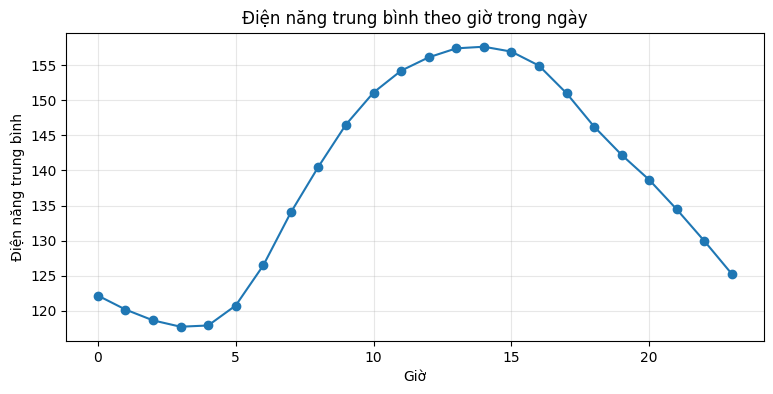

In [20]:
df.groupby('hour').electricity.mean().plot(marker='o', figsize=(9, 4))
plt.title('Điện năng trung bình theo giờ trong ngày')
plt.xlabel('Giờ')
plt.ylabel('Điện năng trung bình')
plt.grid(alpha=0.3)
plt.show()

### 5.2. Điện trung bình theo ngày trong tháng

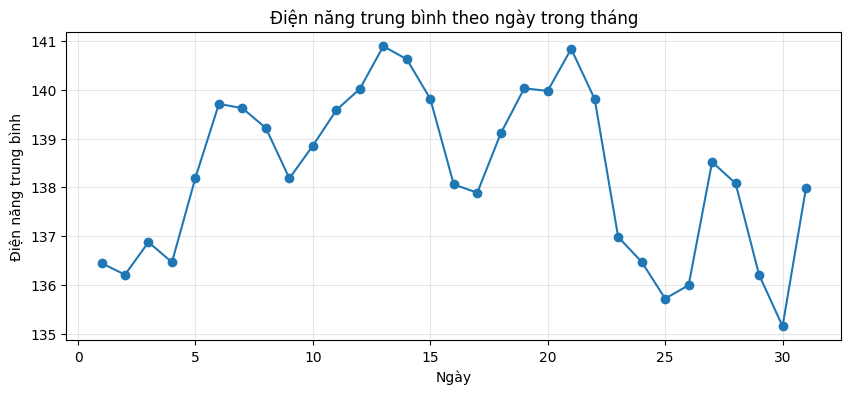

In [21]:
df.groupby('day').electricity.mean().plot(marker='o', figsize=(10, 4))
plt.title('Điện năng trung bình theo ngày trong tháng')
plt.xlabel('Ngày')
plt.ylabel('Điện năng trung bình')
plt.grid(alpha=0.3)
plt.show()

### 5.3. Điện trung bình theo tháng trong năm

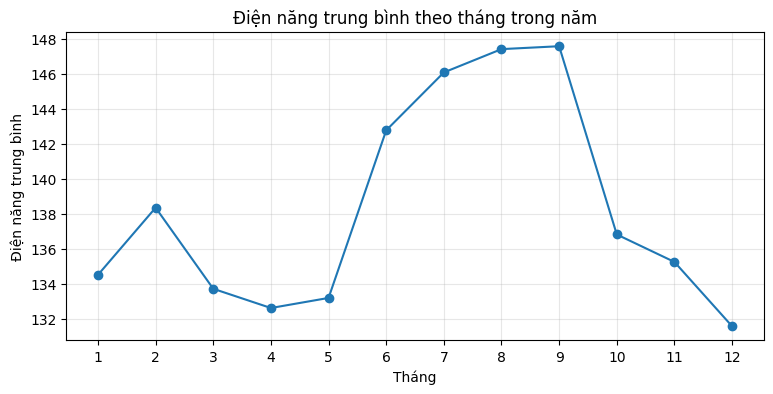

In [22]:
monthly_mean = df.groupby('month')['electricity'].mean().sort_index()
plt.figure(figsize=(9, 4))
plt.plot(monthly_mean.index, monthly_mean.values, marker='o')
plt.title('Điện năng trung bình theo tháng trong năm')
plt.xlabel('Tháng')
plt.ylabel('Điện năng trung bình')
plt.xticks(monthly_mean.index)
plt.grid(True, alpha=0.3)
plt.show()

### 5.4. Điện ngày thường và cuối tuần

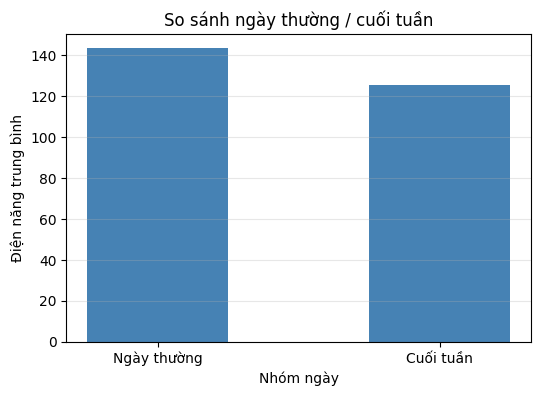

In [23]:
df['weekend'] = (df['weekday'] >= 5).astype(int)

weekend_mean = df.groupby('weekend')['electricity'].mean()
weekend_mean.index = ['Ngày thường', 'Cuối tuần']

plt.figure(figsize=(6, 4))
plt.bar(weekend_mean.index, weekend_mean.values, color='steelblue', width=0.5)

plt.title('So sánh ngày thường / cuối tuần')
plt.xlabel('Nhóm ngày')
plt.ylabel('Điện năng trung bình')
plt.grid(axis='y', alpha=0.3)

plt.show()

### 5.5. Heatmap hành vi tiêu thụ điện theo giờ và thứ
Biểu đồ thể hiện điện năng trung bình tại mỗi giờ trong tuần của các tòa nhà được chọn. Màu sáng nghĩa là tiêu thụ cao hơn.

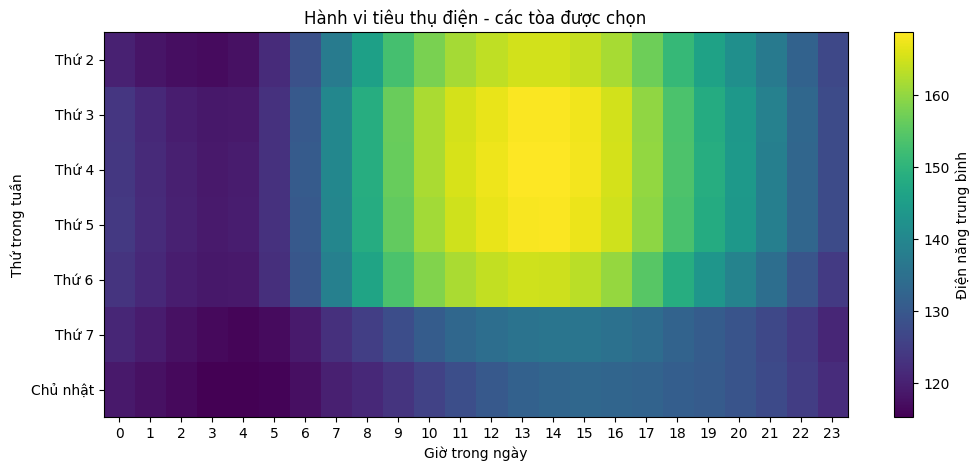

In [24]:
# Điện năng trung bình theo giờ và thứ trong tuần
heatmap_data = df.pivot_table(
    index='weekday',
    columns='hour',
    values='electricity',
    aggfunc='mean'
).reindex(index=range(7), columns=range(24))

plt.figure(figsize=(12, 5))
plt.imshow(heatmap_data, aspect='auto', cmap='viridis')
plt.colorbar(label='Điện năng trung bình')
plt.xticks(range(24))
plt.yticks(range(7), ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ nhật'])
plt.xlabel('Giờ trong ngày')
plt.ylabel('Thứ trong tuần')
plt.title('Hành vi tiêu thụ điện - các tòa được chọn')
plt.show()

## 6. Chia tập huấn luyện / tập xác thực / tập kiểm tra theo thời gian
tập huấn luyện: 2016; tập xác thực: nửa đầu 2017; tập kiểm tra: nửa cuối 2017. Không chia ngẫu nhiên từng dòng.

In [25]:
df = df.sort_values(['building_id', 'timestamp']).reset_index(drop=True)
is_train = (df.timestamp < train_end) & df.electricity.notna()
is_val = (df.timestamp >= train_end) & (df.timestamp < val_end) & df.electricity.notna()
is_test = (df.timestamp >= val_end) & df.electricity.notna()
print('Train:', is_train.sum())
print('Validation:', is_val.sum())
print('Test:', is_test.sum())

Train: 12707212
Validation: 6383737
Test: 6496358


## 7. Thuật toán cơ bản — Dự báo cùng giờ hôm trước
phương pháp cơ sở đơn giản: lượng điện dự báo bằng lượng điện cùng giờ ngày hôm trước.

In [26]:
df['lag24'] = df.groupby('building_id').raw_kwh.shift(24)
val_base = df.loc[is_val & df.lag24.notna()].copy()
test_base = df.loc[is_test & df.lag24.notna()].copy()
print('Mẫu baseline Validation:', len(val_base))
print('Mẫu baseline Test:', len(test_base))

Mẫu baseline Validation: 6358891
Mẫu baseline Test: 6478461


### 7.1. Đánh giá baseline

In [27]:
def danh_gia(y, pred):
    y = np.asarray(y)
    pred = np.asarray(pred)
    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    wape = 100 * np.abs(y - pred).sum() / max(np.abs(y).sum(), 1e-9)
    r2 = r2_score(y, pred)
    return {'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape, 'R2': r2}

baseline_val = danh_gia(val_base.electricity, val_base.lag24)  # Chỉ các giờ có lag24
baseline_test = danh_gia(test_base.electricity, test_base.lag24)
display(pd.DataFrame([baseline_val, baseline_test], index=['Validation', 'Test']).round(3))

,MAE,RMSE,WAPE (%),R2
Validation,13.545,81.602,9.903,0.891
Test,14.149,108.940,10.322,0.817


### 7.2. Biểu đồ baseline của một tòa nhà

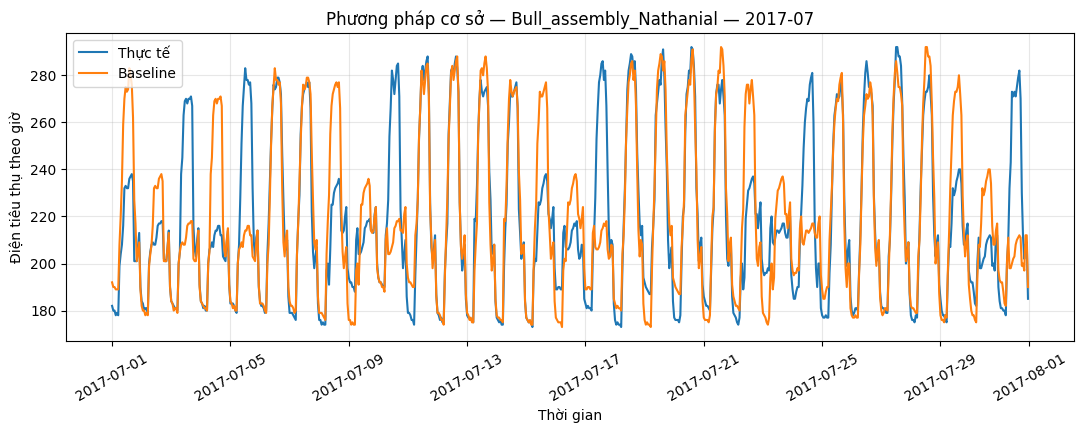

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
selected_id = BUILDING_ID if BUILDING_ID is not None else rng.choice(sorted(usable))
if selected_id not in set(usable):
    raise ValueError('BUILDING_ID không thuộc các tòa hợp lệ')

# Baseline: hiển thị toàn bộ tháng đầu của tập kiểm tra (thay vì chỉ 7 ngày).
example = test_base[test_base.building_id == selected_id].copy()
if example.empty:
    print('Tòa được chọn chưa có mẫu Baseline trong tập kiểm tra.')
else:
    month_first = example.timestamp.dt.to_period('M').min()
    example = example[example.timestamp.dt.to_period('M') == month_first]
    plt.figure(figsize=(13, 4))
    plt.plot(example.timestamp, example.electricity, label='Thực tế')
    plt.plot(example.timestamp, example.lag24, label='Baseline')
    plt.title(f'Phương pháp cơ sở — {selected_id} — {month_first}')
    plt.xlabel('Thời gian')
    plt.ylabel('Điện tiêu thụ theo giờ')
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.show()

## 8. Tạo đặc trưng để cải tiến mô hình
Lag/rolling được tính riêng từng tòa. Chỉ lấy thông tin đã biết trước thời điểm cần dự báo.

In [29]:
df['lag168'] = df.groupby('building_id').raw_kwh.shift(168)
df['rolling24'] = df.groupby('building_id').raw_kwh.transform(
    lambda x: x.shift(24).rolling(24, min_periods=12).mean())
df['temp_lag24'] = df.groupby('building_id').airTemperature.shift(24)
df['building_code'] = pd.Categorical(df.building_id).codes
if 'primaryspaceusage' in df.columns:
    df['usage_code'] = pd.Categorical(df.primaryspaceusage.fillna('Unknown')).codes
else:
    df['usage_code'] = 0

### 8.1. Chọn các đặc trưng

In [30]:
features = ['hour', 'weekday', 'month', 'weekend', 'building_code',
            'usage_code', 'lag24', 'lag168', 'rolling24', 'temp_lag24']
print('Các đặc trưng:', features)
display(df[features + ['electricity']].head())

Các đặc trưng: ['hour', 'weekday', 'month', 'weekend', 'building_code', 'usage_code', 'lag24', 'lag168', 'rolling24', 'temp_lag24']


,hour,weekday,month,weekend,building_code,usage_code,lag24,lag168,rolling24,temp_lag24,electricity
0,0,4,1,0,0,1,NaN,NaN,NaN,NaN,237.850006
1,1,4,1,0,0,1,NaN,NaN,NaN,NaN,221.250000
2,2,4,1,0,0,1,NaN,NaN,NaN,NaN,222.500000
3,3,4,1,0,0,1,NaN,NaN,NaN,NaN,221.399994
4,4,4,1,0,0,1,NaN,NaN,NaN,NaN,224.250000


### 8.2. Chuẩn bị tập huấn luyện, tập xác thực và tập kiểm tra
Giá trị thiếu trong đặc trưng được thay bằng median tính trên tập huấn luyện, không lấy từ tập xác thực/tập kiểm tra.

In [31]:
median_train = df.loc[is_train, features].median().fillna(0)
X_train = df.loc[is_train, features].fillna(median_train)
X_val = df.loc[is_val, features].fillna(median_train)
X_test = df.loc[is_test, features].fillna(median_train)
y_train = df.loc[is_train, 'electricity']
y_val = df.loc[is_val, 'electricity']
y_test = df.loc[is_test, 'electricity']
print(X_train.shape, X_val.shape, X_test.shape)

(12707212, 10) (6383737, 10) (6496358, 10)


## 9. Thuật toán nâng cao — Random Forest
Random Forest học từ nhiều tòa nhà; giới hạn số mẫu tập huấn luyện để phù hợp máy RAM 16 GB.

In [32]:
# Huấn luyện Random Forest trên toàn bộ tập Train
rf = RandomForestRegressor(
    n_estimators=60,
    max_depth=15,
    min_samples_leaf=8,
    n_jobs=2,
    random_state=RANDOM_STATE
)

rf.fit(X_train, y_train)

rf_val = rf.predict(X_val)

print('Huấn luyện Random Forest xong')

Huấn luyện Random Forest xong


### 9.1. Đánh giá Random Forest trên tập xác thực

In [33]:
# So sánh trên cùng các giờ đã có baseline.
valid_common = df.loc[is_val, 'lag24'].notna().to_numpy()
rf_result = danh_gia(y_val.to_numpy()[valid_common], rf_val[valid_common])
compare = pd.DataFrame([baseline_val, rf_result], index=['Baseline', 'Random Forest'])

### 9.2. Thuật toán nâng cao thứ hai — LightGBM
Nếu chưa có LightGBM, cài bằng `pip install lightgbm`.

In [34]:
from lightgbm import LGBMRegressor
lgbm = LGBMRegressor(n_estimators=220, learning_rate=0.06,
                     num_leaves=31, n_jobs=2, verbosity=-1, random_state=RANDOM_STATE)
lgbm.fit(X_train, y_train)
lgb_val = lgbm.predict(X_val)
lgb_result = danh_gia(y_val.to_numpy()[valid_common], lgb_val[valid_common])
compare.loc['LightGBM'] = lgb_result
display(compare.round(3))

,MAE,RMSE,WAPE (%),R2
Baseline,13.545,81.602,9.903,0.891
Random Forest,10.918,37.648,7.982,0.977
LightGBM,12.168,39.260,8.896,0.975


### 9.3. So sánh và chọn mô hình dựa trên tập xác thực

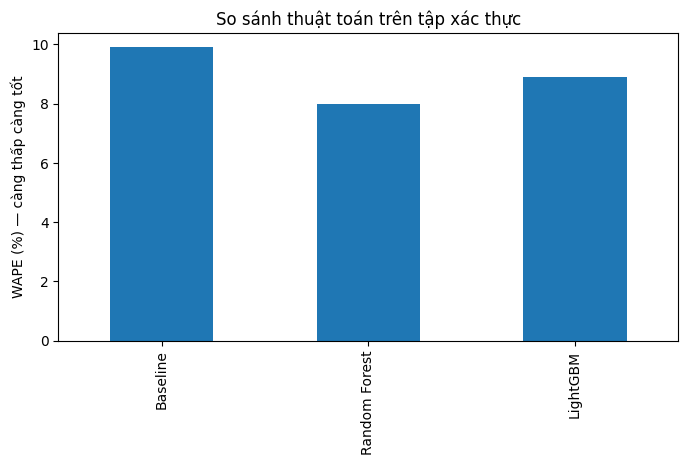

Phương pháp được chọn: Random Forest


In [35]:
compare['WAPE (%)'].plot.bar(figsize=(8, 4))
plt.ylabel('WAPE (%) — càng thấp càng tốt')
plt.title('So sánh thuật toán trên tập xác thực')
plt.show()
chosen = compare['WAPE (%)'].idxmin()
print('Phương pháp được chọn:', chosen)

### 9.4. Đánh giá cuối trên tập kiểm tra
Chỉ lựa chọn bằng tập xác thực. tập kiểm tra chỉ dùng để báo cáo kết quả.

In [36]:
if chosen == 'Baseline':
    df['prediction'] = df.lag24
else:
    # Chỉ cần dự báo trên tập xác thực + Test để đánh giá và phát hiện bất thường.
    df['prediction'] = np.nan
    valid_period = df.timestamp >= train_end
    data_predict = df.loc[valid_period, features].fillna(median_train)
    if chosen == 'Random Forest':
        df.loc[valid_period, 'prediction'] = rf.predict(data_predict)
    else:
        df.loc[valid_period, 'prediction'] = lgbm.predict(data_predict)

test_final = df.loc[is_test & df.prediction.notna()].copy()
final_result = danh_gia(test_final.electricity, test_final.prediction)
display(pd.DataFrame([final_result], index=[chosen]).round(3))

,MAE,RMSE,WAPE (%),R2
Random Forest,11.484,45.603,8.379,0.968


### 9.5. So sánh điện thực tế và dự báo theo ngày trên tập kiểm tra
Hiển thị các ngày có số liệu. Ngày thiếu giờ vẫn được vẽ theo **tổng số giờ ghi nhận** và có dấu riêng, không coi là tổng 24 giờ.

Tòa nhà: Bull_assembly_Nathanial
Số ngày có dữ liệu: 184
Số ngày đủ 24 giờ: 158
Số ngày thiếu giờ: 26


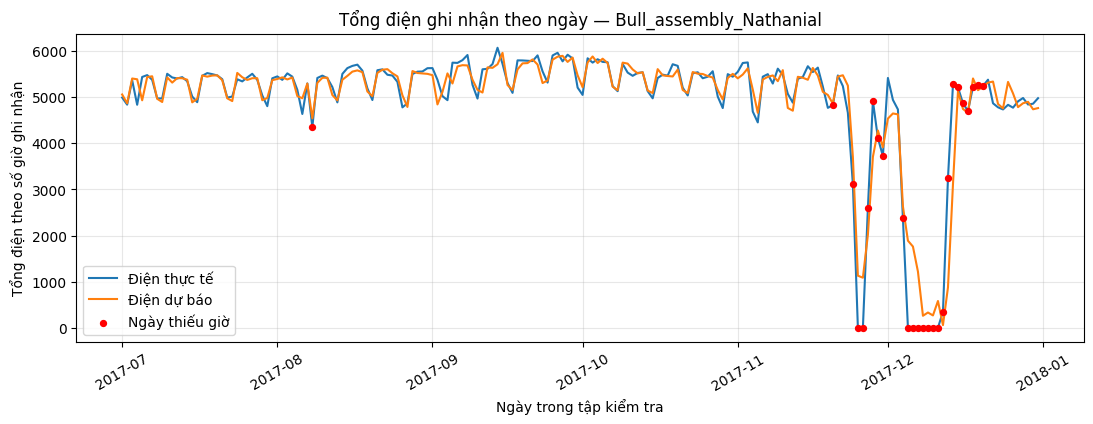

Lưu ý: ngày thiếu 24 giờ chỉ được cộng từ các giờ có dữ liệu; không phải tổng điện cả ngày.


In [37]:
# Gộp các giờ có điện thực tế và dự báo để so sánh công bằng.
one = test_final[test_final.building_id == selected_id].copy()
one['ngay'] = one.timestamp.dt.floor('D')
daily_test = one.groupby('ngay').agg(
    thuc_te=('electricity', 'sum'),
    du_bao=('prediction', 'sum'),
    so_gio=('timestamp', 'nunique')
)
print('Tòa nhà:', selected_id)
print('Số ngày có dữ liệu:', len(daily_test))
print('Số ngày đủ 24 giờ:', int((daily_test.so_gio == 24).sum()))
print('Số ngày thiếu giờ:', int((daily_test.so_gio < 24).sum()))

plt.figure(figsize=(13, 4))
plt.plot(daily_test.index, daily_test.thuc_te, label='Điện thực tế')
plt.plot(daily_test.index, daily_test.du_bao, label='Điện dự báo')
thieu = daily_test[daily_test.so_gio < 24]
if not thieu.empty:
    plt.scatter(thieu.index, thieu.thuc_te, color='red', s=18,
                label='Ngày thiếu giờ', zorder=4)
plt.title(f'Tổng điện ghi nhận theo ngày — {selected_id}')
plt.xlabel('Ngày trong tập kiểm tra')
plt.ylabel('Tổng điện theo số giờ ghi nhận')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()
print('Lưu ý: ngày thiếu 24 giờ chỉ được cộng từ các giờ có dữ liệu; không phải tổng điện cả ngày.')

### 9.6. Xem độ quan trọng của đặc trưng

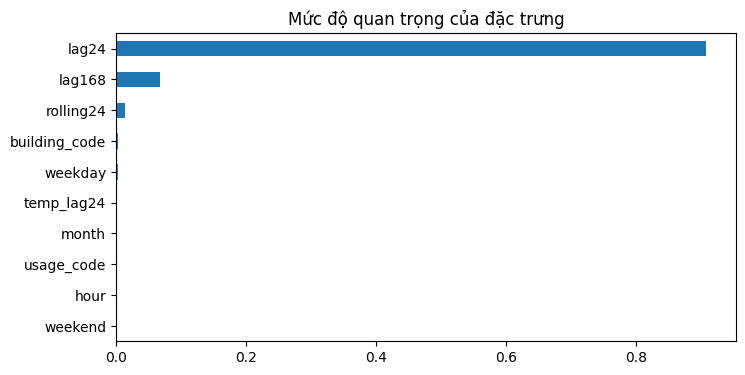

In [38]:
if chosen == 'Random Forest':
    importance = rf.feature_importances_
elif chosen == 'LightGBM':
    importance = lgbm.feature_importances_
else:
    importance = None
if importance is not None:
    pd.Series(importance, index=features).sort_values().plot.barh(figsize=(8, 4))
    plt.title('Mức độ quan trọng của đặc trưng')
    plt.show()

## 10. Trực quan dự báo theo giờ, ngày, tháng
Chọn **một tòa nhà** đã được huấn luyện, sau đó so sánh điện thực tế và dự báo ở ba cách nhìn.

In [39]:
# Danh sách các tòa nhà có dữ liệu dự báo
ds_toa_nha = sorted(
    df.loc[
        df['prediction'].notna() & df['electricity'].notna(),
        'building_id'
    ].unique()
)

print('Số tòa nhà có thể chọn:', len(ds_toa_nha))
print(ds_toa_nha)

Số tòa nhà có thể chọn: 1497
['Bear_assembly_Angel', 'Bear_assembly_Beatrice', 'Bear_assembly_Danial', 'Bear_assembly_Diana', 'Bear_assembly_Genia', 'Bear_assembly_Harry', 'Bear_assembly_Jose', 'Bear_assembly_Roxy', 'Bear_assembly_Ruby', 'Bear_education_Alfredo', 'Bear_education_Alvaro', 'Bear_education_Arnold', 'Bear_education_Augusta', 'Bear_education_Austin', 'Bear_education_Babara', 'Bear_education_Benita', 'Bear_education_Benjamin', 'Bear_education_Bob', 'Bear_education_Bonita', 'Bear_education_Bulah', 'Bear_education_Carlo', 'Bear_education_Chad', 'Bear_education_Chana', 'Bear_education_Chun', 'Bear_education_Clint', 'Bear_education_Curtis', 'Bear_education_Danna', 'Bear_education_Darrell', 'Bear_education_Deborah', 'Bear_education_Deena', 'Bear_education_Derek', 'Bear_education_Destiny', 'Bear_education_Elise', 'Bear_education_Fannie', 'Bear_education_Gavin', 'Bear_education_Herb', 'Bear_education_Herman', 'Bear_education_Holly', 'Bear_education_Irene', 'Bear_education_Iris', 'B

In [55]:
# Nhập ID tòa nhà muốn dự báo
selected_id = 'Bull_assembly_Nathanial'

if selected_id not in ds_toa_nha:
    raise ValueError('Tòa nhà này không có dữ liệu dự báo hợp lệ.')

print('Tòa nhà được chọn:', selected_id)

# selected_id = np.random.choice(ds_toa_nha)
# print('Tòa nhà ngẫu nhiên:', selected_id)

Tòa nhà được chọn: Bull_assembly_Nathanial


In [56]:
one_all = df.loc[
    (df.building_id == selected_id) &
    (df.timestamp.dt.year == 2017) &
    df.electricity.notna() &
    df.prediction.notna(),
    ['timestamp', 'electricity', 'prediction']
].copy()
one_all = one_all.sort_values('timestamp')
print('Tòa nhà:', selected_id)
print('Khoảng dữ liệu dự báo:', one_all.timestamp.min(), 'đến', one_all.timestamp.max())
print('Số giờ hợp lệ:', len(one_all))
if one_all.empty:
    raise ValueError('Tòa nhà được chọn không có dữ liệu dự báo hợp lệ trong năm 2017.')

Tòa nhà: Bull_assembly_Nathanial
Khoảng dữ liệu dự báo: 2017-01-01 00:00:00 đến 2017-12-31 23:00:00
Số giờ hợp lệ: 8551


### 10.1. Dự báo **giờ trong ngày**
Chọn một ngày có đủ 24 giờ, để thấy lượng điện thực tế và dự báo từ 0 giờ đến 23 giờ.

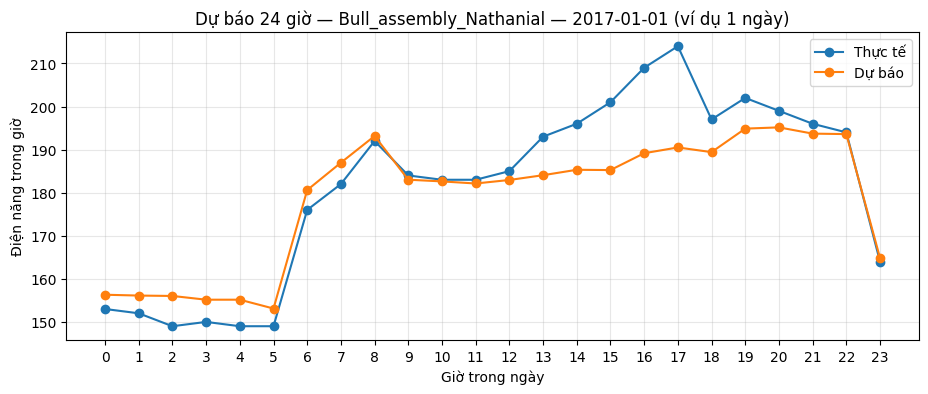

Đây là ví dụ một ngày; biểu đồ tổng ngày ở trên bao quát toàn bộ tập kiểm tra.


In [57]:
one_all['date'] = one_all.timestamp.dt.floor('D')
valid_dates = one_all.groupby('date').timestamp.nunique()
valid_dates = valid_dates[valid_dates == 24].index
if len(valid_dates) == 0:
    print('Không có ngày đủ 24 giờ để vẽ theo giờ.')
else:
    selected_date = valid_dates[0]
    hourly = one_all[one_all.date == selected_date].copy()
    hourly['hour'] = hourly.timestamp.dt.hour
    plt.figure(figsize=(11, 4))
    plt.plot(hourly.hour, hourly.electricity, marker='o', label='Thực tế')
    plt.plot(hourly.hour, hourly.prediction, marker='o', label='Dự báo')
    plt.title(f'Dự báo 24 giờ — {selected_id} — {selected_date.date()} (ví dụ 1 ngày)')
    plt.xlabel('Giờ trong ngày')
    plt.ylabel('Điện năng trong giờ')
    plt.xticks(range(24))
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    print('Đây là ví dụ một ngày; biểu đồ tổng ngày ở trên bao quát toàn bộ tập kiểm tra.')

### 10.2. So sánh điện theo ngày trong tháng
Vẽ tổng các giờ có số liệu theo từng ngày; đánh dấu ngày thiếu giờ để dễ nhận biết.

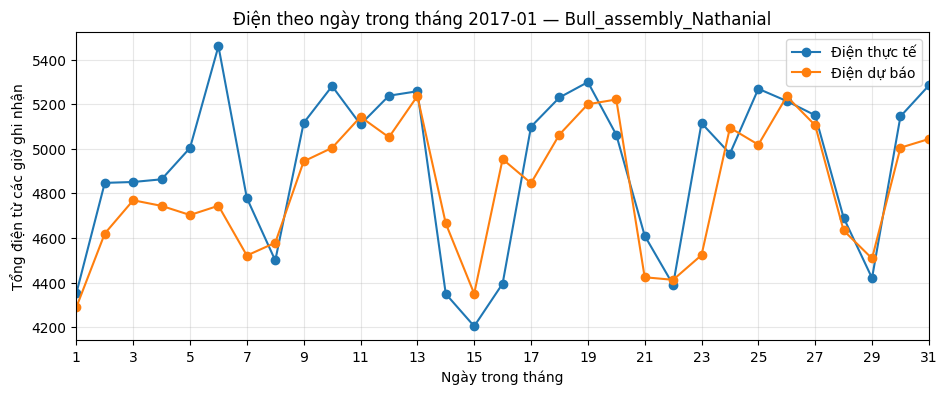

Các ngày thiếu giờ có tổng điện chưa đầy đủ; không tự điền dữ liệu.


In [58]:
by_day = one_all.groupby('date').agg(
    thuc_te=('electricity', 'sum'),
    du_bao=('prediction', 'sum'),
    so_gio=('timestamp', 'nunique')
)
if by_day.empty:
    print('Không có dữ liệu ngày để vẽ.')
else:
    selected_month = one_all.timestamp.dt.to_period('M').value_counts().idxmax()
    ngay_thang = pd.date_range(selected_month.start_time,
                              selected_month.end_time.floor('D'))
    theo_ngay = by_day.reindex(ngay_thang)
    plt.figure(figsize=(11, 4))
    plt.plot(theo_ngay.index.day, theo_ngay.thuc_te,
             marker='o', label='Điện thực tế')
    plt.plot(theo_ngay.index.day, theo_ngay.du_bao,
             marker='o', label='Điện dự báo')
    thieu = theo_ngay[theo_ngay.so_gio < 24]
    if not thieu.empty:
        plt.scatter(thieu.index.day, thieu.thuc_te, color='red', s=35,
                    label='Ngày thiếu giờ', zorder=4)
    plt.title(f'Điện theo ngày trong tháng {selected_month} — {selected_id}')
    plt.xlabel('Ngày trong tháng')
    plt.ylabel('Tổng điện từ các giờ ghi nhận')
    plt.xticks(range(1, selected_month.days_in_month + 1, 2))
    plt.xlim(1, selected_month.days_in_month)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    print('Các ngày thiếu giờ có tổng điện chưa đầy đủ; không tự điền dữ liệu.')

### 10.3. So sánh điện theo tháng trong năm 2017
Nối các tháng có dữ liệu để dễ nhìn xu hướng. Số liệu là **tổng điện ở những giờ có ghi nhận**, không phải tổng tháng đầy đủ nếu thiếu giờ.

Tỷ lệ số giờ có dữ liệu của từng tháng (%):


,so_gio,gio_can_co,ty_le_du_lieu
thang,,,
2017-01,744,744,100.0
2017-02,672,672,100.0
2017-03,743,744,99.9
2017-04,719,720,99.9
2017-05,744,744,100.0
2017-06,720,720,100.0
2017-07,744,744,100.0
2017-08,741,744,99.6
2017-09,720,720,100.0


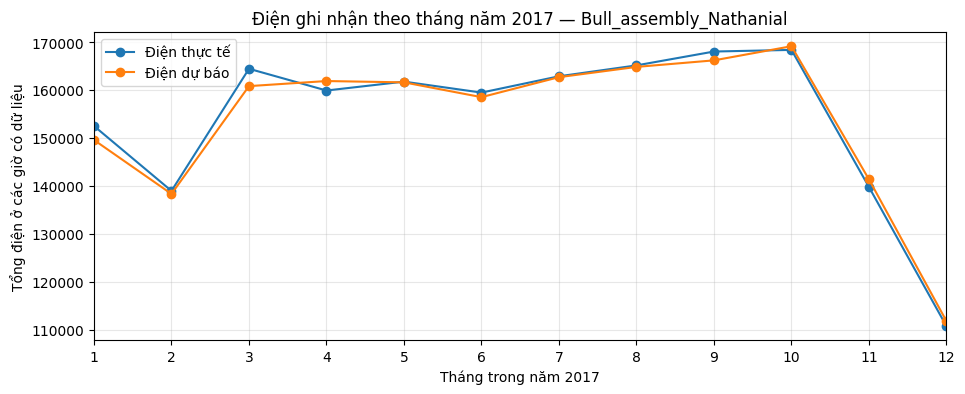

Chú ý: đường nối chỉ giúp theo dõi xu hướng. Tháng thiếu giờ có tổng chưa đầy đủ;
tháng hoàn toàn không có dữ liệu không được tính hay ước lượng.


In [59]:
one_all['thang'] = one_all.timestamp.dt.to_period('M')
by_month = one_all.groupby('thang').agg(
    thuc_te=('electricity', 'sum'),
    du_bao=('prediction', 'sum'),
    so_gio=('timestamp', 'nunique')
)
by_month['gio_can_co'] = by_month.index.days_in_month * 24
by_month['ty_le_du_lieu'] = by_month.so_gio / by_month.gio_can_co * 100
print('Tỷ lệ số giờ có dữ liệu của từng tháng (%):')
display(by_month[['so_gio', 'gio_can_co', 'ty_le_du_lieu']].round(1))

# Chỉ vẽ các tháng có số liệu. Đường nối qua tháng trống không có nghĩa
# rằng ta đã dự báo hoặc biết tổng điện của các tháng đó.
thang_co_du_lieu = by_month.copy()
thang_co_du_lieu['so_thang'] = thang_co_du_lieu.index.month
plt.figure(figsize=(11, 4))
plt.plot(thang_co_du_lieu.so_thang, thang_co_du_lieu.thuc_te,
         marker='o', label='Điện thực tế')
plt.plot(thang_co_du_lieu.so_thang, thang_co_du_lieu.du_bao,
         marker='o', label='Điện dự báo')
plt.title(f'Điện ghi nhận theo tháng năm 2017 — {selected_id}')
plt.xlabel('Tháng trong năm 2017')
plt.ylabel('Tổng điện ở các giờ có dữ liệu')
plt.xticks(range(1, 13))
plt.xlim(1, 12)
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print('Chú ý: đường nối chỉ giúp theo dõi xu hướng. Tháng thiếu giờ có tổng chưa đầy đủ;')
print('tháng hoàn toàn không có dữ liệu không được tính hay ước lượng.')

## 11. Phát hiện bất thường từ sai số dự báo trên dữ liệu gốc

### 11.1. Dự báo tại các thời điểm raw của tập xác thực và tập kiểm tra

In [45]:
# Dự báo đã có ở cột prediction (từ bước đánh giá Test).
raw_val = (df.timestamp >= train_end) & (df.timestamp < val_end) & df.raw_kwh.notna() & df.prediction.notna()
raw_test = (df.timestamp >= val_end) & df.raw_kwh.notna() & df.prediction.notna()
df['abs_residual'] = (df.raw_kwh - df.prediction).abs()
print('Điểm kiểm tra raw trên tập kiểm tra:', raw_test.sum())

Điểm kiểm tra raw trên tập kiểm tra: 6544120


### 11.2. Xác định ngưỡng theo từng tòa từ tập xác thực
Lấy phân vị 99% sai số tuyệt đối theo tòa để cảnh báo các sai lệch lớn.

In [46]:
threshold = df.loc[raw_val].groupby('building_id').abs_residual.quantile(0.99)
global_threshold = df.loc[raw_val, 'abs_residual'].quantile(0.99)
df = df.join(threshold.rename('threshold'), on='building_id')
df['threshold'] = df.threshold.fillna(global_threshold)
df['residual_alarm'] = df.abs_residual > df.threshold
print('Ngưỡng chung dự phòng:', round(global_threshold, 3))

Ngưỡng chung dự phòng: 131.192


### 11.3. Isolation Forest — phương pháp so sánh
Dùng điện raw và thời gian để phát hiện các điểm khác thường; mô hình được học trên tập huấn luyện.

In [47]:
iso_features = ['raw_kwh', 'hour', 'weekday', 'month']
iso_train = df.loc[(df.timestamp < train_end) & df.raw_kwh.notna(), iso_features]
iso_sample = iso_train.sample(n=min(60000, len(iso_train)), random_state=RANDOM_STATE)
iso = IsolationForest(n_estimators=100, contamination=0.01,
                      random_state=RANDOM_STATE, n_jobs=2)
iso.fit(iso_sample)
print('Isolation Forest đã huấn luyện')

Isolation Forest đã huấn luyện


### 11.4. So sánh các phương pháp phát hiện

In [48]:
df['iso_alarm'] = False
rows_raw = df.index[raw_test]
iso_predictions = iso.predict(df.loc[rows_raw, iso_features])
df.loc[rows_raw, 'iso_alarm'] = iso_predictions == -1
df['both_alarm'] = df.residual_alarm & df.iso_alarm
stats = pd.Series({
    'Residual': df.loc[raw_test, 'residual_alarm'].sum(),
    'Isolation Forest': df.loc[raw_test, 'iso_alarm'].sum(),
    'Cả hai': df.loc[raw_test, 'both_alarm'].sum()
})
display(stats.to_frame('Số cảnh báo'))

,Số cảnh báo
Residual,97952
Isolation Forest,57265
Cả hai,4925


### 11.5. Kiểm thử bằng bất thường mô phỏng
Chèn tăng/giảm bất thường vào một bản sao những điểm raw tập kiểm tra, **không thay đổi dữ liệu gốc**. Chỉ số phản ánh khả năng bắt được bất thường chèn, không phải nhãn sự cố thật.

In [49]:
normal = df.loc[raw_test & ~df.residual_alarm & ~df.iso_alarm].copy()
normal = normal.dropna(subset=['raw_kwh', 'prediction', 'threshold'])
normal = normal.sample(n=min(5000, len(normal)), random_state=RANDOM_STATE).copy()
if len(normal) < 20:
    raise ValueError('Không đủ điểm nền để mô phỏng bất thường.')
normal['simulated'] = normal.raw_kwh
normal['label'] = 0
rng = np.random.default_rng(RANDOM_STATE)
positions = rng.choice(normal.index, size=max(1, int(len(normal) * 0.1)), replace=False)
half = len(positions) // 2
normal.loc[positions[:half], 'simulated'] *= 3
normal.loc[positions[half:], 'simulated'] *= 0.1
normal.loc[positions, 'label'] = 1

### 11.6. Đánh giá Độ chính xác cảnh báo, Độ bao phủ bất thường, F1 trên dữ liệu mô phỏng

In [50]:
sim_alarm = (normal.simulated - normal.prediction).abs() > normal.threshold
print('Precision:', round(precision_score(normal.label, sim_alarm, zero_division=0), 3))
print('Recall:', round(recall_score(normal.label, sim_alarm, zero_division=0), 3))
print('F1:', round(f1_score(normal.label, sim_alarm, zero_division=0), 3))
print('Confusion matrix:\n', confusion_matrix(normal.label, sim_alarm))

Precision: 1.0
Recall: 0.73
F1: 0.844
Confusion matrix:
 [[4500    0]
 [ 135  365]]


### 11.7. Trực quan các điểm bất thường của tòa được chọn

Số giờ dữ liệu gốc được kiểm tra: 4379
Số cảnh báo: 74
Số giờ dữ liệu gốc bằng 0: 0
Số giờ dữ liệu gốc tăng hơn 3 lần dự báo: 27
Chú ý: các số đo bằng 0 hoặc đột biến lớn cần kiểm tra công tơ, không mặc định là sự cố thực.


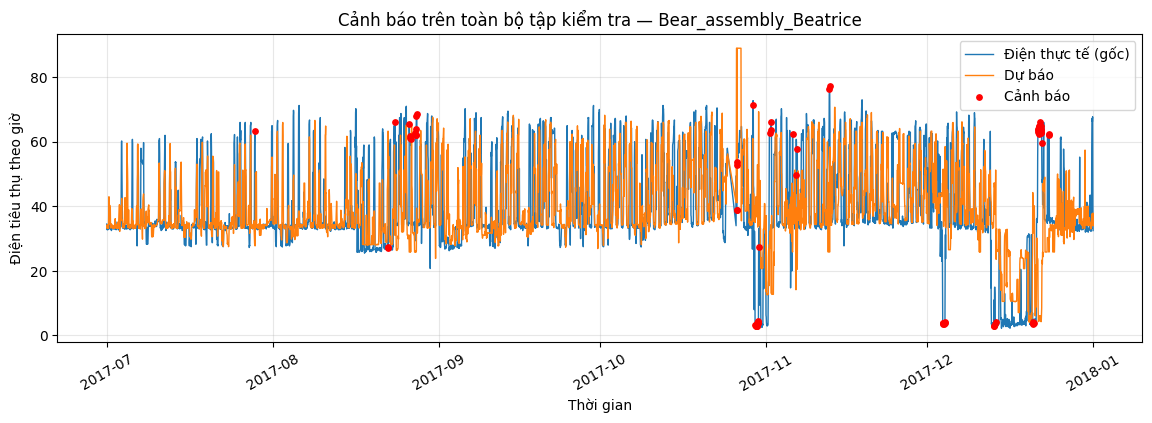

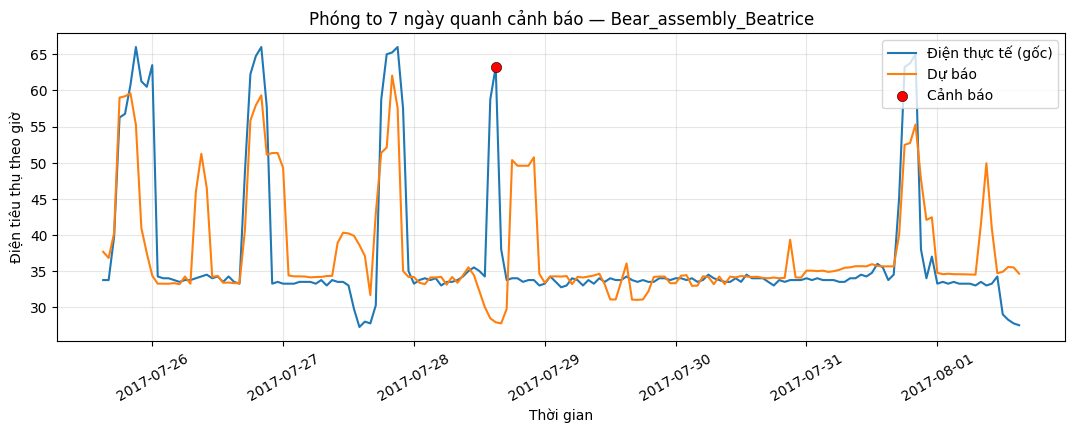

In [51]:
# Biểu đồ 1: toàn bộ tập kiểm tra, đánh dấu tất cả cảnh báo được phát hiện.
selected_test = df.loc[raw_test & df.building_id.eq(selected_id)].copy()
selected_test = selected_test.sort_values('timestamp')
if selected_test.empty:
    print('Không có dữ liệu raw của tòa nhà này trong tập kiểm tra.')
else:
    selected_test['any_alarm'] = selected_test.residual_alarm | selected_test.iso_alarm
    alarms = selected_test[selected_test.any_alarm]
    print('Số giờ dữ liệu gốc được kiểm tra:', len(selected_test))
    print('Số cảnh báo:', len(alarms))
    print('Số giờ dữ liệu gốc bằng 0:', int((selected_test.raw_kwh == 0).sum()))
    print('Số giờ dữ liệu gốc tăng hơn 3 lần dự báo:', int((selected_test.raw_kwh > 3 * selected_test.prediction).sum()))
    print('Chú ý: các số đo bằng 0 hoặc đột biến lớn cần kiểm tra công tơ, không mặc định là sự cố thực.')

    plt.figure(figsize=(14, 4))
    plt.plot(selected_test.timestamp, selected_test.raw_kwh, label='Điện thực tế (gốc)', linewidth=1)
    plt.plot(selected_test.timestamp, selected_test.prediction, label='Dự báo', linewidth=1)
    if not alarms.empty:
        plt.scatter(alarms.timestamp, alarms.raw_kwh, s=15,
                    color='red', label='Cảnh báo', zorder=5)
    plt.title(f'Cảnh báo trên toàn bộ tập kiểm tra — {selected_id}')
    plt.xlabel('Thời gian')
    plt.ylabel('Điện tiêu thụ theo giờ')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=30)
    plt.show()

    # Biểu đồ 2: phóng to 7 ngày quanh một cảnh báo (nếu có).
    if not alarms.empty:
        center = alarms.timestamp.iloc[0]
        start = center - pd.Timedelta(days=3)
        end = center + pd.Timedelta(days=4)
        zoom = selected_test[selected_test.timestamp.between(start, end)].copy()
        marked = zoom[zoom.any_alarm]
        plt.figure(figsize=(13, 4))
        plt.plot(zoom.timestamp, zoom.raw_kwh, label='Điện thực tế (gốc)')
        plt.plot(zoom.timestamp, zoom.prediction, label='Dự báo')
        plt.scatter(marked.timestamp, marked.raw_kwh, s=55, color='red',
                    edgecolors='black', linewidths=0.4, zorder=5, label='Cảnh báo')
        plt.title(f'Phóng to 7 ngày quanh cảnh báo — {selected_id}')
        plt.xlabel('Thời gian')
        plt.ylabel('Điện tiêu thụ theo giờ')
        plt.legend()
        plt.grid(alpha=0.3)
        plt.xticks(rotation=30)
        plt.show()

### 11.8. Cảnh báo theo giờ trong ngày

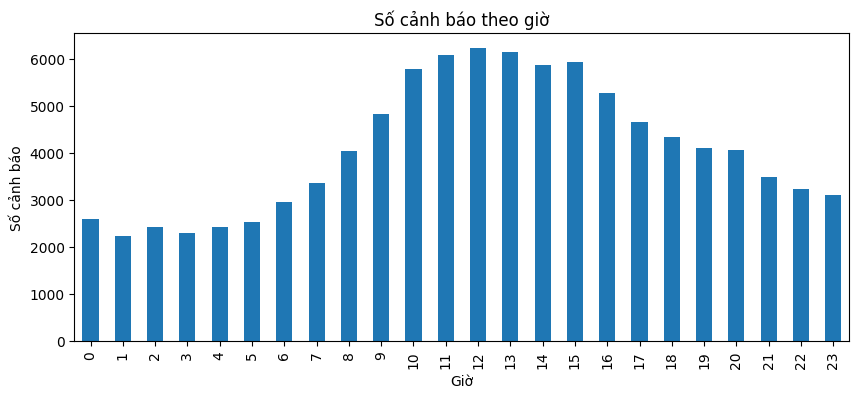

In [52]:
alarm_all = df.loc[raw_test & df.residual_alarm].copy()
alarm_all.groupby('hour').size().reindex(range(24), fill_value=0).plot.bar(figsize=(10, 4))
plt.title('Số cảnh báo theo giờ')
plt.xlabel('Giờ')
plt.ylabel('Số cảnh báo')
plt.show()

## 12. Xuất kết quả và đánh giá tổng kết

In [53]:
result = df.loc[raw_test & (df.residual_alarm | df.iso_alarm),
    ['building_id', 'timestamp', 'raw_kwh', 'prediction', 'abs_residual',
     'threshold', 'residual_alarm', 'iso_alarm']].copy()
result['anomaly_type'] = np.where(result.raw_kwh > result.prediction,
                                   'Tăng bất thường', 'Giảm bất thường')
result['severity'] = np.where(result.abs_residual > result.threshold * 2,
                              'Nghiêm trọng', 'Cảnh báo')
result.to_csv(OUTPUT_DIR / 'bat_thuong.csv', index=False, encoding='utf-8-sig')
compare.to_csv(OUTPUT_DIR / 'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
print('Số cảnh báo:', len(result))
display(result.head(10))

Số cảnh báo: 150292


,building_id,timestamp,raw_kwh,prediction,abs_residual,threshold,residual_alarm,iso_alarm,anomaly_type,severity
14736,Bear_assembly_Angel,2017-09-06 00:00:00,240.772705,576.759604,335.986899,317.231676,True,False,Giảm bất thường,Cảnh báo
14737,Bear_assembly_Angel,2017-09-06 01:00:00,222.500000,576.759604,354.259604,317.231676,True,False,Giảm bất thường,Cảnh báo
14738,Bear_assembly_Angel,2017-09-06 02:00:00,217.250000,576.759604,359.509604,317.231676,True,False,Giảm bất thường,Cảnh báo
14739,Bear_assembly_Angel,2017-09-06 03:00:00,220.246902,576.759604,356.512702,317.231676,True,False,Giảm bất thường,Cảnh báo
14740,Bear_assembly_Angel,2017-09-06 04:00:00,235.488907,580.775099,345.286192,317.231676,True,False,Giảm bất thường,Cảnh báo
14902,Bear_assembly_Angel,2017-09-12 22:00:00,651.750000,332.331267,319.418733,317.231676,True,False,Tăng bất thường,Cảnh báo
14904,Bear_assembly_Angel,2017-09-13 00:00:00,564.019470,233.761871,330.257599,317.231676,True,False,Tăng bất thường,Cảnh báo
14908,Bear_assembly_Angel,2017-09-13 04:00:00,591.726929,242.923680,348.803249,317.231676,True,False,Tăng bất thường,Cảnh báo
15430,Bear_assembly_Angel,2017-10-04 22:00:00,332.751007,655.833476,323.082469,317.231676,True,False,Giảm bất thường,Cảnh báo
15435,Bear_assembly_Angel,2017-10-05 03:00:00,233.500000,553.529368,320.029368,317.231676,True,False,Giảm bất thường,Cảnh báo


### 12.1. Đánh giá dự báo theo từng tòa

In [54]:
per_building = []
for building, group in test_final.groupby('building_id'):
    row = danh_gia(group.electricity, group.prediction)
    row['building_id'] = building
    per_building.append(row)
per_building = pd.DataFrame(per_building).set_index('building_id')
display(per_building.sort_values('WAPE (%)').head(10).round(3))
per_building.to_csv(OUTPUT_DIR / 'danh_gia_tung_toa.csv', encoding='utf-8-sig')

,MAE,RMSE,WAPE (%),R2
building_id,,,,
Bear_parking_Gordon,0.335,0.497,1.187,0.271
Bear_education_Zandra,11.675,16.897,1.265,0.786
Fox_education_Otilia,13.018,19.977,1.373,0.820
Fox_education_Claude,13.987,21.895,1.413,0.613
Fox_education_Wendell,7.811,13.155,1.473,0.852
Moose_education_Maria,14.340,25.080,1.536,-0.596
Fox_education_Theodore,4.261,9.052,1.564,0.367
Bull_education_Barry,15.929,55.337,1.581,-0.317
Cockatoo_education_Tyler,12.884,19.175,1.727,0.786


### 12.2. Kết luận
So sánh chất lượng dự báo và số lượng cảnh báo; kết quả bất thường mô phỏng chưa phải độ chính xác trên bất thường thực tế.